In [28]:
import numpy as np
import altair as alt
import json
import seaborn as sns 
from evaluation.avalanche_criterion import avalanche_criterion
from evaluation.fixed_points import fixed_ponts
from evaluation.uniformity import get_ddt
from evaluation.linearity import evaluate
from sboxes.loader import load as load_sbox
from sboxes import SBox
from sboxes.loader import load as load_sbox
from evaluation.identity_sbox import IdentitySBox

from evaluation.graphics.graphics_with_altair import (
    compare_tv_distance_altair,
    compare_max_probability_altair,
    compare_mixing_times_altair,
    compare_mixing_times_spectrals_altair
)

# Para que Altair muestre los charts en el notebook
alt.renderers.enable('default')

RendererRegistry.enable('default')

In [29]:
from evaluation.fixed_points      import fixed_ponts

number_of_owns = 50
own_sboxes_index = range(1,number_of_owns+1)

indexes = []

for i in own_sboxes_index:
    with open(f"data/5x5_sboxes/sbox_5_{i}.json", "r", encoding="utf-8") as f:
        data = json.load(f)
        table = list(map(lambda x: hex(x), data["best"]))
        n_in  = int(np.log2(len(table)))                    # size of the input
        n_out = int(np.ceil(np.log2(max(data["best"])+1)))  # size of the output
        name = f"Variant #{i}"    
        sbox = SBox(n_in, n_out, table, name)                    
        fijos = fixed_ponts(sbox, detail=True)[1]
        if fijos == 0:
            indexes.append(i)
print(f"{indexes}")

[3, 4, 5, 9, 19, 21, 23, 24, 25, 27, 35, 36, 42, 43, 45, 46, 49, 50]


In [30]:
selected = [4, 9, 21, 43, 49, 50]

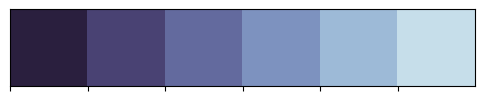

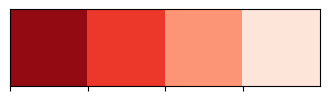

In [31]:
number_of_owns = len(selected)
own_sboxes_index = selected

COLORS_FOR_OWNS = sns.color_palette("ch:s=.25,rot=-.25", n_colors=number_of_owns) [::-1]
#sns.palplot(sns.color_palette("Reds", n_colors=10))[::-3]  # Colores para las S-Boxes propias
COLORS_FOR_CLASICS = sns.color_palette("Reds", n_colors=10)[::-3]
sns.palplot(COLORS_FOR_OWNS)
sns.palplot(COLORS_FOR_CLASICS)

In [32]:
to_proof = ["ascon", "fides_5_AB"]
specs_clasics = []

for sbox_link in to_proof:
    sbox = load_sbox(f"data/clasics/{sbox_link}.json")
    specs_clasics.append({
        'name': sbox.name,
        'table': sbox.table.tolist(),
        'n_in': sbox.input_size,
        'n_out': sbox.output_size,
        'color': COLORS_FOR_CLASICS[len(specs_clasics) % len(COLORS_FOR_CLASICS)],
        'sbox': sbox
        
    })
    print(f"Procesando S-Box: {sbox.name} ({sbox.input_size}x{sbox.output_size})")

Procesando S-Box: ASCON (5x5)
Procesando S-Box: FIDES_5 (5x5)


In [33]:
specs_owns = []

for i in own_sboxes_index:

    with open(f"data/5x5_sboxes/sbox_5_{i}.json", "r", encoding="utf-8") as f:
        data = json.load(f)
    
        table = list(map(lambda x: hex(x), data["best"]))
        n_in  = int(np.log2(len(table)))                    # size of the input
        n_out = int(np.ceil(np.log2(max(data["best"])+1)))  # size of the output
        name = f"Variant #{i}"
            
        sbox = SBox(n_in, n_out, table, name)                    
        specs_owns.append({
            "name": name,              
            "table": data["best"],
            "n_in": n_in,
            "n_out": n_out,
            "color": COLORS_FOR_OWNS[len(specs_owns) % len(COLORS_FOR_OWNS)],
            "sbox":  sbox
        })

print(f"{len(specs_owns)} S-Boxes cargadas desde data.json")


6 S-Boxes cargadas desde data.json


In [34]:

specs = specs_clasics + specs_owns

import matplotlib.colors as mcolors
for spec in specs:
    spec['color'] = mcolors.to_hex(spec['color'])

In [35]:
chart_tv = compare_tv_distance_altair(
    specs,
    r_values=list(range(1,16)),
    log_scale=True,
    detail=True
)
chart_tv

|   r |       ASCON |     FIDES_5 |   Variant #21 |   Variant #4 |   Variant #43 |   Variant #49 |   Variant #50 |   Variant #9 |
|----:|------------:|------------:|--------------:|-------------:|--------------:|--------------:|--------------:|-------------:|
|   1 | 0.870968    | 0.483871    |   0.580645    |  0.612903    |   0.612903    |   0.612903    |   0.580645    |  0.580645    |
|   2 | 0.429435    | 0.0680444   |   0.119708    |  0.122606    |   0.133317    |   0.128402    |   0.126512    |  0.111895    |
|   3 | 0.167465    | 0.0114352   |   0.0236344   |  0.0251937   |   0.0264144   |   0.0281549   |   0.0266271   |  0.0254379   |
|   4 | 0.0489384   | 0.00227602  |   0.00521703  |  0.00547938  |   0.00491382  |   0.0061803   |   0.00591992  |  0.00540013  |
|   5 | 0.0189406   | 0.00039919  |   0.00105433  |  0.00110577  |   0.00102086  |   0.00128888  |   0.00129552  |  0.00121538  |
|   6 | 0.00697487  | 7.11256e-05 |   0.000192986 |  0.000233129 |   0.000210093 |   0.000

alt.Chart(...)

In [36]:
chart_mp = compare_max_probability_altair(
    specs,
    r_values=list(range(1,11)),
    log_scale=False,
    detail=True
)
chart_mp

|   r |     ASCON |   FIDES_5 |   Variant #21 |   Variant #4 |   Variant #43 |   Variant #49 |   Variant #50 |   Variant #9 |
|----:|----------:|----------:|--------------:|-------------:|--------------:|--------------:|--------------:|-------------:|
|   1 | 0.25      | 0.0625    |     0.125     |    0.125     |     0.125     |     0.125     |     0.125     |    0.125     |
|   2 | 0.109375  | 0.0390625 |     0.0507812 |    0.0625    |     0.0546875 |     0.0546875 |     0.0546875 |    0.0625    |
|   3 | 0.0566406 | 0.0351562 |     0.036377  |    0.0366211 |     0.0371094 |     0.0373535 |     0.0375977 |    0.0368652 |
|   4 | 0.041748  | 0.0327148 |     0.0331726 |    0.0334473 |     0.0332947 |     0.0332031 |     0.0336761 |    0.0335083 |
|   5 | 0.0351257 | 0.0323486 |     0.0324163 |    0.0324898 |     0.0324793 |     0.0324812 |     0.0325079 |    0.0324736 |
|   6 | 0.0334053 | 0.0322742 |     0.0322915 |    0.0323071 |     0.0322986 |     0.032308  |     0.0323071 |    0.03

alt.Chart(...)

In [37]:
chart_mix = compare_mixing_times_altair(
    specs,
    epsilons=[10**(-i) for i in range(6,7)],
    max_steps=10000,
)
chart_mix

[1e-06]
ASCON with ε=1e-06: 15
FIDES_5 with ε=1e-06: 9
Variant #4 with ε=1e-06: 10
Variant #9 with ε=1e-06: 10
Variant #21 with ε=1e-06: 10
Variant #43 with ε=1e-06: 10
Variant #49 with ε=1e-06: 10
Variant #50 with ε=1e-06: 10


alt.Chart(...)

In [38]:
chart_spec = compare_mixing_times_spectrals_altair(
    specs,
    epsilons=[10**(-i) for i in range(1,11)],
    max_steps=10000,
)
chart_spec

alt.Chart(...)

# Clasicas


=== Métricas de S-Boxes ===
       name  uniformity  max_ddt  fixed_points  non_linearity  avg_sac  max_std_sac
      ASCON           8       32             0            8.0    0.620     0.374166
    FIDES_5           2       32             0           12.0    0.540     0.200000
 Variant #4           4       32             0           10.0    0.495     0.145774
 Variant #9           4       32             0           10.0    0.530     0.176777
Variant #21           4       32             0           10.0    0.540     0.127475
Variant #43           4       32             0           10.0    0.490     0.136931
Variant #49           4       32             0           10.0    0.495     0.127475
Variant #50           4       32             0           10.0    0.525     0.145774


c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


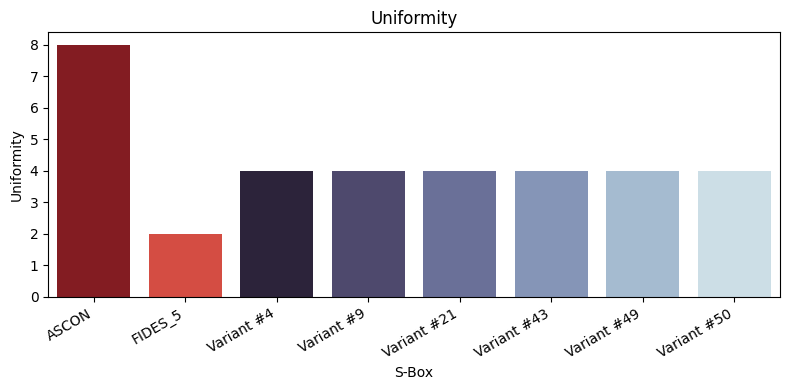

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


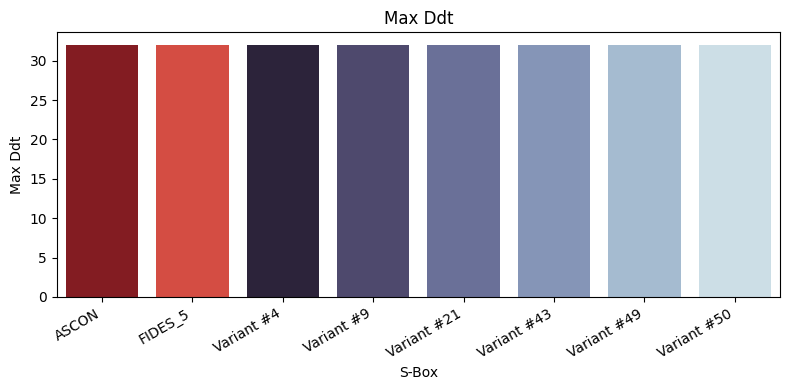

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


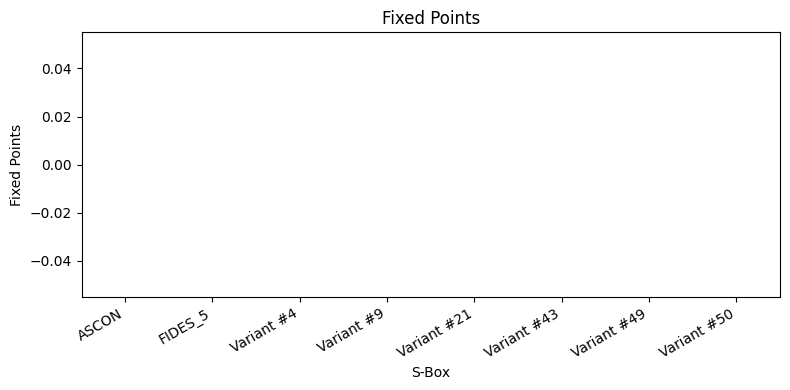

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


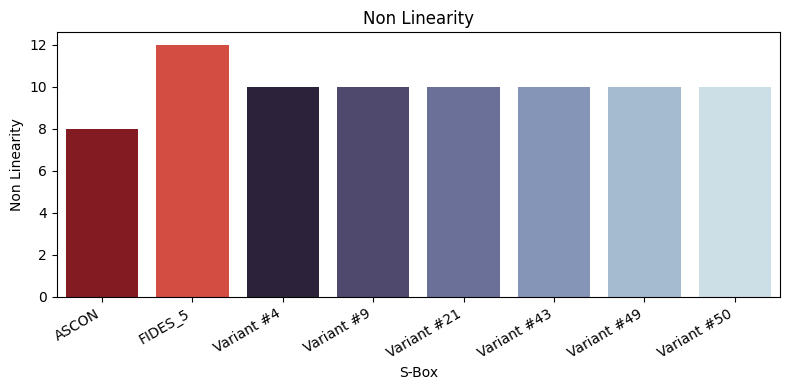

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


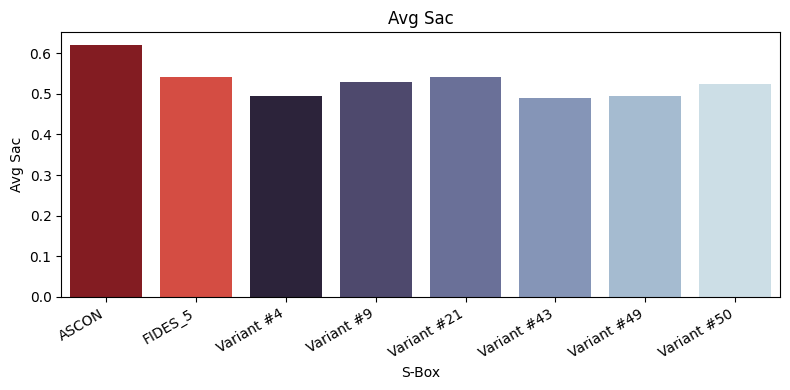

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


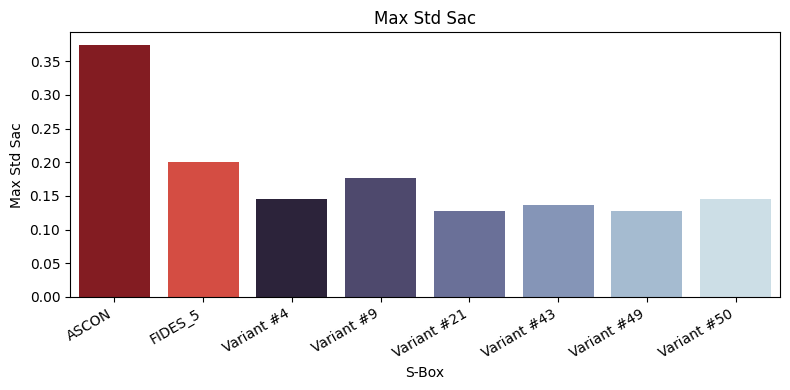

,name,uniformity,max_ddt,fixed_points,non_linearity,avg_sac,max_std_sac
0,ASCON,8,32,0,8.0,0.620,0.374166
1,FIDES_5,2,32,0,12.0,0.540,0.200000
2,Variant #4,4,32,0,10.0,0.495,0.145774
3,Variant #9,4,32,0,10.0,0.530,0.176777
4,Variant #21,4,32,0,10.0,0.540,0.127475
5,Variant #43,4,32,0,10.0,0.490,0.136931
6,Variant #49,4,32,0,10.0,0.495,0.127475
7,Variant #50,4,32,0,10.0,0.525,0.145774


In [39]:
from evaluation.sbox_metrics_analysis import run_all_metrics

run_all_metrics(specs)

# Ranking

In [40]:
import pandas as pd

# Carga el resumen de métricas generado por run_all_metrics
df = pd.read_csv('sbox_metrics_summary.csv')

# Calcula desviación de avg_sac respecto a 0.5 (ideal SAC = 0.5)
df['sac_error'] = (df['avg_sac'] - 0.5).abs()

# Genera rankings individuales (menor es mejor salvo non_linearity)
df['r_uniformity']    = df['uniformity'].rank(ascending=True)
df['r_max_ddt']       = df['max_ddt'].rank(ascending=True)
df['r_fixed_points']  = df['fixed_points'].rank(ascending=True)
df['r_non_linearity'] = df['non_linearity'].rank(ascending=False)
df['r_sac_error']     = df['sac_error'].rank(ascending=True)
df['r_max_std_sac']   = df['max_std_sac'].rank(ascending=True)

# Suma de rangos como puntaje agregado
rank_cols = ['r_uniformity','r_max_ddt','r_fixed_points',
             'r_non_linearity','r_sac_error','r_max_std_sac']
df['total_rank'] = df[rank_cols].sum(axis=1)

# Ordena y muestra top 5
top5 = df.sort_values('total_rank').reset_index(drop=True)
to_display = top5[['name','total_rank','non_linearity','uniformity',
                   'fixed_points','avg_sac','max_ddt','max_std_sac']].head(5)

import ace_tools as tools; tools.display_dataframe_to_user(name="Top 5 S-Boxes por puntaje agregado", dataframe=to_display)


ModuleNotFoundError: No module named 'ace_tools'